# Example of variance decomposition

Collinearity diagnostics for a design matrix: correlations, variance inflation factors, condition indexes and the variance-decomposition proportions of Belsley, Kuh and Welsch (1980).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.set_printoptions(suppress=True)

In [2]:
X = pd.DataFrame(np.array([
    [-74,  80,  18,    -56,   -112],
    [ 14, -69,  21,     52,    104],
    [ 66, -72,  -5,    764,   1528],
    [-12,  66, -30,   4096,   8192],
    [  3,   8,  -7, -13276, -26552],
    [  4, -12,   4,   8421,  16842]]), columns=['x1', 'x2', 'x3', 'x4', 'x5'])
X

,x1,x2,x3,x4,x5
0,-74,80,18,-56,-112
1,14,-69,21,52,104
2,66,-72,-5,764,1528
3,-12,66,-30,4096,8192
4,3,8,-7,-13276,-26552
5,4,-12,4,8421,16842


The last column is exactly two times the fourth one, so the matrix does not have full rank and its condition number is huge.

In [3]:
print(f'Condition number: {np.linalg.cond(X):.3g}')

Condition number: 3.94e+16


In [4]:
def plot_heatmap(ax, values, row_labels, col_labels, cmap, vmin, vmax, fmt='{:.2f}', white_above=0.6):
    # Annotated heatmap with a white gap between the cells
    im = ax.imshow(values, cmap=cmap, vmin=vmin, vmax=vmax)
    n_rows, n_cols = values.shape
    for i in range(n_rows):
        for j in range(n_cols):
            dark = abs(values[i, j]) > white_above*max(abs(vmin), abs(vmax))
            ax.text(j, i, fmt.format(round(values[i, j], 2) + 0), ha='center', va='center', fontsize=12,
                    color='white' if dark else '#333333')
    ax.set_xticks(range(n_cols), col_labels)
    ax.set_yticks(range(n_rows), row_labels)
    ax.set_xticks(np.arange(n_cols+1)-0.5, minor=True)
    ax.set_yticks(np.arange(n_rows+1)-0.5, minor=True)
    ax.grid(which='minor', color='white', linewidth=3)
    ax.tick_params(which='both', length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return im

## Correlation matrix

The correlation matrix shows the collinearity between `x4` and `x5`, but correlations only detect relations between pairs of variables.

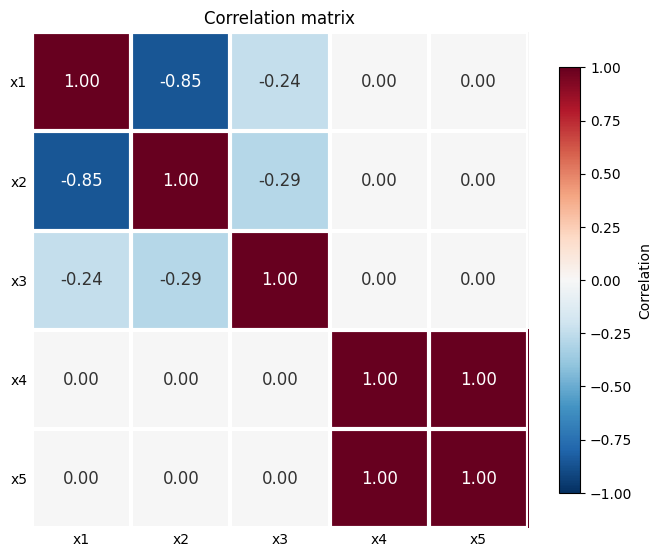

In [5]:
corr_matrix = X.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = plot_heatmap(ax, corr_matrix.to_numpy(), X.columns, X.columns, 'RdBu_r', -1, 1)
fig.colorbar(im, ax=ax, label='Correlation', shrink=0.85)
ax.set_title('Correlation matrix');

## Variance inflation factors

$\mathrm{VIF}_j = 1/(1-R_j^2)$, where $R_j^2$ is the coefficient of determination of the regression of the $j$-th variable on the others. Values larger than 5 may indicate collinearity. Here $R^2 = 1$ for `x4` and `x5`, so their VIF is infinite.

In [6]:
with np.errstate(divide='ignore'):
    vif = pd.DataFrame({
        'feature': X.columns,
        'VIF': np.round([variance_inflation_factor(X.values, j) for j in range(X.shape[1])], 2)})
vif

,feature,VIF
0,x1,55.68
1,x2,57.17
2,x3,16.53
3,x4,inf
4,x5,inf


## Singular value decomposition and condition indexes

With $X = UDV^T$, the condition indexes are $\eta_k = d_{\max}/d_k$. A condition index larger than 30 points to a collinearity, there are as many collinearities as large condition indexes.

In [7]:
u, d, vt = np.linalg.svd(X)
v = vt.T

# Singular values
d

array([36368.40448796,   170.70133054,    60.53318792,     7.60190176,
           0.        ])

In [8]:
# Condition indexes
cond_index = d[0]/d
cond_index

array([1.00000000e+00, 2.13052847e+02, 6.00801077e+02, 4.78411924e+03,
       3.93970797e+16])

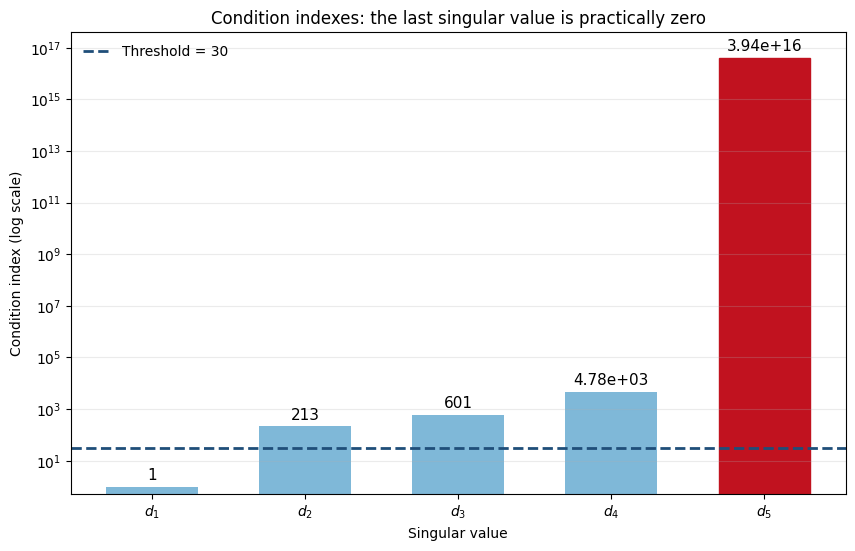

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
components = [f'$d_{k+1}$' for k in range(len(d))]
bars = ax.bar(components, cond_index, color='#7fb8d8', width=0.6)
bars[-1].set_color('#c1121f')
ax.axhline(30, ls='--', color='#1f4e79', lw=2, label='Threshold = 30')
for k, value in enumerate(cond_index):
    ax.annotate(f'{value:.3g}', (k, value), xytext=(0, 5), textcoords='offset points', ha='center', fontsize=11)
ax.set_yscale('log')
ax.set_ylim(0.5, 10*cond_index.max())
ax.set_xlabel('Singular value')
ax.set_ylabel('Condition index (log scale)')
ax.set_title('Condition indexes: the last singular value is practically zero')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, axis='y', alpha=0.25)

## Variance-decomposition proportions

Since $\mathrm{Var}(\hat\beta_j) = \sigma^2\sum_k v_{jk}^2/d_k^2$, the proportion of the variance of $\hat\beta_j$ associated with the $k$-th singular value is
$$\pi_{kj} = \frac{\phi_{jk}}{\sum_k \phi_{jk}}, \qquad \phi_{jk} = \frac{v_{jk}^2}{d_k^2}.$$
The variables involved in a collinearity are the ones with a high proportion (more than 0.5) of their variance in a row with a large condition index.

Here the last singular value takes all the variance of `x4` and `x5` (the exact collinearity). The fourth one, with a condition index of 4784, takes almost all the variance of `x1`, `x2` and `x3`: there is a second collinearity among them, which the correlation matrix did not show clearly.

In [10]:
phis = v**2/d**2
var_decomp_proportions = phis.T/sum(phis.T)

pd.DataFrame(var_decomp_proportions, index=[f'd{k+1}' for k in range(len(d))], columns=X.columns).round(4)

,x1,x2,x3,x4,x5
d1,0.0000,0.0000,0.0000,0.0,0.0
d2,0.0019,0.0088,0.0000,0.0,0.0
d3,0.0195,0.0147,0.0134,0.0,0.0
d4,0.9786,0.9766,0.9866,0.0,0.0
d5,0.0000,0.0000,0.0000,1.0,1.0


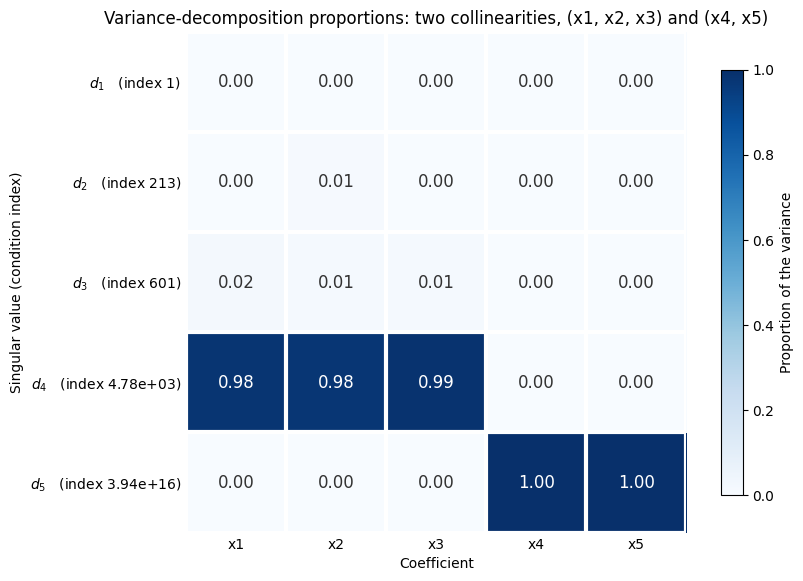

In [11]:
fig, ax = plt.subplots(figsize=(9, 6.5))
row_labels = [f'$d_{k+1}$   (index {cond_index[k]:.3g})' for k in range(len(d))]
im = plot_heatmap(ax, var_decomp_proportions, row_labels, X.columns, 'Blues', 0, 1)
fig.colorbar(im, ax=ax, label='Proportion of the variance', shrink=0.85)
ax.set_xlabel('Coefficient')
ax.set_ylabel('Singular value (condition index)')
ax.set_title('Variance-decomposition proportions: two collinearities, (x1, x2, x3) and (x4, x5)');